### 1 : Load and Validate Analytical Artifacts


In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path("..") if Path("../data").exists() else Path(".")

data_jd_path = project_root / "data" / "job-descriptions-tagged.csv"
data_skills_path = project_root / "data" / "skill-list.csv"
out_eval_path = project_root / "outputs" / "evaluation_labels.csv"
out_syn_path = project_root / "outputs" / "synonym_mapping.csv"
out_rubric_path = project_root / "outputs" / "annotation_rubric.md"
out_b_per_jd_path = project_root / "outputs" / "per_jd_metrics.csv"
out_b_overall_path = project_root / "outputs" / "overall_metrics.csv"
out_b_error_path = project_root / "outputs" / "error_analysis.csv"
out_b_fp_path = project_root / "outputs" / "false_positive_analysis.csv"
out_b_fn_path = project_root / "outputs" / "false_negative_analysis.csv"
out_m1_per_jd_path = project_root / "outputs" / "improvement_per_jd_metrics.csv"
out_m1_overall_path = project_root / "outputs" / "improvement_overall_metrics.csv"
out_m1_comp_path = project_root / "outputs" / "improvement_comparison.csv"
out_m1_err_path = project_root / "outputs" / "improvement_error_analysis.csv"

def sha256_file(filepath):
    return hashlib.sha256(Path(filepath).read_bytes()).hexdigest()

assert sha256_file(data_jd_path) == "7822ec510c9fdc4435b7d29db01357386f4dfa125d86185485967b82b568867d"
assert sha256_file(data_skills_path) == "9f78f1822dce52cbe2492b54c70006fad7a77334e1b074411f4e28db982fcec2"

df_jd = pd.read_csv(data_jd_path)
df_skills = pd.read_csv(data_skills_path)
df_eval = pd.read_csv(out_eval_path)
df_syn = pd.read_csv(out_syn_path)
df_b_per_jd = pd.read_csv(out_b_per_jd_path)
df_b_overall = pd.read_csv(out_b_overall_path)
df_b_error = pd.read_csv(out_b_error_path)
df_b_fp = pd.read_csv(out_b_fp_path)
df_b_fn = pd.read_csv(out_b_fn_path)
df_m1_per_jd = pd.read_csv(out_m1_per_jd_path)
df_m1_overall = pd.read_csv(out_m1_overall_path)
df_m1_comp = pd.read_csv(out_m1_comp_path)
df_m1_err = pd.read_csv(out_m1_err_path)

assert len(df_jd) == 50
assert len(df_skills) == 54
assert len(df_eval) == 50
assert len(df_b_per_jd) == 50
assert len(df_m1_per_jd) == 50

artifact_load_status = pd.DataFrame([
    {"Artifact": "Job Descriptions Corpus", "File": data_jd_path.name, "Rows": len(df_jd), "Status": "Verified"},
    {"Artifact": "Canonical Skill Taxonomy", "File": data_skills_path.name, "Rows": len(df_skills), "Status": "Verified"},
    {"Artifact": "Ground-Truth Labels", "File": out_eval_path.name, "Rows": len(df_eval), "Status": "Verified"},
    {"Artifact": "Baseline Per-JD Metrics", "File": out_b_per_jd_path.name, "Rows": len(df_b_per_jd), "Status": "Verified"},
    {"Artifact": "M1 Improved Per-JD Metrics", "File": out_m1_per_jd_path.name, "Rows": len(df_m1_per_jd), "Status": "Verified"}
])
artifact_load_status


,Artifact,File,Rows,Status
0,Job Descriptions Corpus,job-descriptions-tagged.csv,50,Verified
1,Canonical Skill Taxonomy,skill-list.csv,54,Verified
2,Ground-Truth Labels,evaluation_labels.csv,50,Verified
3,Baseline Per-JD Metrics,per_jd_metrics.csv,50,Verified
4,M1 Improved Per-JD Metrics,improvement_per_jd_metrics.csv,50,Verified


### 2 : Final Performance Comparison


In [2]:
b_tp = int(df_b_per_jd["tp"].sum())
b_fp = int(df_b_per_jd["fp"].sum())
b_fn = int(df_b_per_jd["fn"].sum())
b_p_micro = b_tp / (b_tp + b_fp)
b_r_micro = b_tp / (b_tp + b_fn)
b_f1_micro = 2 * b_p_micro * b_r_micro / (b_p_micro + b_r_micro)
b_p_macro = float(df_b_per_jd["precision"].mean())
b_r_macro = float(df_b_per_jd["recall"].mean())
b_f1_macro = float(df_b_per_jd["f1"].mean())
b_req_r = int(df_b_per_jd["required_tp"].sum()) / (int(df_b_per_jd["required_tp"].sum()) + int(df_b_per_jd["required_fn"].sum()))
b_pref_r = int(df_b_per_jd["preferred_tp"].sum()) / (int(df_b_per_jd["preferred_tp"].sum()) + int(df_b_per_jd["preferred_fn"].sum()))

m1_tp = int(df_m1_per_jd["tp"].sum())
m1_fp = int(df_m1_per_jd["fp"].sum())
m1_fn = int(df_m1_per_jd["fn"].sum())
m1_p_micro = m1_tp / (m1_tp + m1_fp)
m1_r_micro = m1_tp / (m1_tp + m1_fn)
m1_f1_micro = 2 * m1_p_micro * m1_r_micro / (m1_p_micro + m1_r_micro)
m1_p_macro = float(df_m1_per_jd["precision"].mean())
m1_r_macro = float(df_m1_per_jd["recall"].mean())
m1_f1_macro = float(df_m1_per_jd["f1"].mean())
m1_req_r = int(df_m1_per_jd["required_tp"].sum()) / (int(df_m1_per_jd["required_tp"].sum()) + int(df_m1_per_jd["required_fn"].sum()))
m1_pref_r = int(df_m1_per_jd["preferred_tp"].sum()) / (int(df_m1_per_jd["preferred_tp"].sum()) + int(df_m1_per_jd["preferred_fn"].sum()))

assert b_tp == 171 and b_fp == 29 and b_fn == 56
assert m1_tp == 171 and m1_fp == 12 and m1_fn == 56
assert round(b_p_micro, 4) == 0.8550
assert round(m1_p_micro, 4) == 0.9344

final_comparison_table = pd.DataFrame([
    {"Metric Scope": "Micro Precision", "Baseline (Original)": f"{b_p_micro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_p_micro * 100:.2f}%", "Absolute Delta": f"+{(m1_p_micro - b_p_micro) * 100:.2f} pp"},
    {"Metric Scope": "Micro Recall", "Baseline (Original)": f"{b_r_micro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_r_micro * 100:.2f}%", "Absolute Delta": f"+{(m1_r_micro - b_r_micro) * 100:.2f} pp"},
    {"Metric Scope": "Micro F1-Score", "Baseline (Original)": f"{b_f1_micro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_f1_micro * 100:.2f}%", "Absolute Delta": f"+{(m1_f1_micro - b_f1_micro) * 100:.2f} pp"},
    {"Metric Scope": "Macro Precision", "Baseline (Original)": f"{b_p_macro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_p_macro * 100:.2f}%", "Absolute Delta": f"+{(m1_p_macro - b_p_macro) * 100:.2f} pp"},
    {"Metric Scope": "Macro Recall", "Baseline (Original)": f"{b_r_macro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_r_macro * 100:.2f}%", "Absolute Delta": f"+{(m1_r_macro - b_r_macro) * 100:.2f} pp"},
    {"Metric Scope": "Macro F1-Score", "Baseline (Original)": f"{b_f1_macro * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_f1_macro * 100:.2f}%", "Absolute Delta": f"+{(m1_f1_macro - b_f1_macro) * 100:.2f} pp"},
    {"Metric Scope": "Required Skill Recall", "Baseline (Original)": f"{b_req_r * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_req_r * 100:.2f}%", "Absolute Delta": "+0.00 pp"},
    {"Metric Scope": "Preferred Skill Recall", "Baseline (Original)": f"{b_pref_r * 100:.2f}%", "M1 Guardrail (Post-Processed)": f"{m1_pref_r * 100:.2f}%", "Absolute Delta": "+0.00 pp"},
    {"Metric Scope": "True Positives (TP)", "Baseline (Original)": str(b_tp), "M1 Guardrail (Post-Processed)": str(m1_tp), "Absolute Delta": "0"},
    {"Metric Scope": "False Positives (FP)", "Baseline (Original)": str(b_fp), "M1 Guardrail (Post-Processed)": str(m1_fp), "Absolute Delta": "-17"},
    {"Metric Scope": "False Negatives (FN)", "Baseline (Original)": str(b_fn), "M1 Guardrail (Post-Processed)": str(m1_fn), "Absolute Delta": "0"}
])
final_comparison_table


,Metric Scope,Baseline (Original),M1 Guardrail (Post-Processed),Absolute Delta
0,Micro Precision,85.50%,93.44%,+7.94 pp
1,Micro Recall,75.33%,75.33%,+0.00 pp
2,Micro F1-Score,80.09%,83.41%,+3.32 pp
3,Macro Precision,87.31%,94.73%,+7.42 pp
4,Macro Recall,74.53%,74.53%,+0.00 pp
5,Macro F1-Score,78.71%,81.67%,+2.96 pp
6,Required Skill Recall,85.31%,85.31%,+0.00 pp
7,Preferred Skill Recall,40.00%,40.00%,+0.00 pp
8,True Positives (TP),171,171,0
9,False Positives (FP),29,12,-17


### 3 : Final Error Analysis


In [3]:
persisting_errors = []
for _, row in df_m1_per_jd.iterrows():
    fps = [t.strip() for t in str(row["incorrect_tags"]).split(";") if t.strip()] if pd.notna(row["incorrect_tags"]) else []
    fns = [t.strip() for t in str(row["missing_tags"]).split(";") if t.strip()] if pd.notna(row["missing_tags"]) else []
    for fp in fps:
        persisting_errors.append({"jd_id": row["jd_id"], "job_title": row["job_title"], "company": row["company"], "error_type": "False Positive (Contextual Spurious)", "skill": fp})
    for fn in fns:
        row_eval = df_eval[df_eval["jd_id"] == row["jd_id"]].iloc[0]
        p_set = set([s.strip() for s in str(row_eval["verified_preferred_skills"]).split(";") if s.strip()])
        tier = "Preferred" if fn in p_set else "Required"
        persisting_errors.append({"jd_id": row["jd_id"], "job_title": row["job_title"], "company": row["company"], "error_type": f"False Negative ({tier} Skill Omission)", "skill": fn})

df_persisting = pd.DataFrame(persisting_errors)
assert len(df_persisting) == 68
assert len(df_persisting[df_persisting["error_type"].str.startswith("False Positive")]) == 12
assert len(df_persisting[df_persisting["error_type"].str.startswith("False Negative (Preferred")]) == 30
assert len(df_persisting[df_persisting["error_type"].str.startswith("False Negative (Required")]) == 26

persisting_summary = df_persisting["error_type"].value_counts().reset_index()
persisting_summary.columns = ["Error Class", "Count"]
persisting_summary["Percentage of Total Remaining Errors"] = persisting_summary["Count"].apply(lambda c: f"{c / 68 * 100:.2f}%")
persisting_summary


,Error Class,Count,Percentage of Total Remaining Errors
0,False Negative (Preferred Skill Omission),30,44.12%
1,False Negative (Required Skill Omission),26,38.24%
2,False Positive (Contextual Spurious),12,17.65%


### 4 : Limitations and Methodological Boundary Statement


In [4]:
limitations_matrix = pd.DataFrame([
    {"Dimension": "1. System Access", "Limitation": "Original model code/weights absent", "Impact": "Internal retraining or architecture tuning impossible", "Status": "Documented"},
    {"Dimension": "2. Input Format", "Limitation": "Static pre-computed tag strings", "Impact": "Inference parameters (temperature, thresholds) cannot be varied", "Status": "Documented"},
    {"Dimension": "3. M1 Nature", "Limitation": "Post-processing ontology filter", "Impact": "Does not represent newly trained ML model", "Status": "Documented"},
    {"Dimension": "4. Ground Truth", "Limitation": "Single-annotator review", "Impact": "Inter-annotator agreement metrics unavailable; span evidence provided", "Status": "Documented"},
    {"Dimension": "5. Corpus Nature", "Limitation": "50 synthetic, templated JDs", "Impact": "Vocabulary and sentence distribution is highly regularized", "Status": "Documented"},
    {"Dimension": "6. Generalization", "Limitation": "Unvalidated on real-world postings", "Impact": "Real-world performance on noisy text remains unmeasured", "Status": "Documented"},
    {"Dimension": "7. Tier Disparity", "Limitation": "40.0% Preferred vs 85.3% Required recall", "Impact": "Candidate ranking remains impaired by secondary omission", "Status": "Documented"},
    {"Dimension": "8. Recall Scope", "Limitation": "56 false negatives unaddressed by M1", "Impact": "Requires upstream generative extraction to resolve", "Status": "Documented"}
])
limitations_matrix


,Dimension,Limitation,Impact,Status
0,1. System Access,Original model code/weights absent,Internal retraining or architecture tuning imp...,Documented
1,2. Input Format,Static pre-computed tag strings,"Inference parameters (temperature, thresholds)...",Documented
2,3. M1 Nature,Post-processing ontology filter,Does not represent newly trained ML model,Documented
3,4. Ground Truth,Single-annotator review,Inter-annotator agreement metrics unavailable;...,Documented
4,5. Corpus Nature,"50 synthetic, templated JDs",Vocabulary and sentence distribution is highly...,Documented
5,6. Generalization,Unvalidated on real-world postings,Real-world performance on noisy text remains u...,Documented
6,7. Tier Disparity,40.0% Preferred vs 85.3% Required recall,Candidate ranking remains impaired by secondar...,Documented
7,8. Recall Scope,56 false negatives unaddressed by M1,Requires upstream generative extraction to res...,Documented


### 5 : Final Diagnostic Visualizations


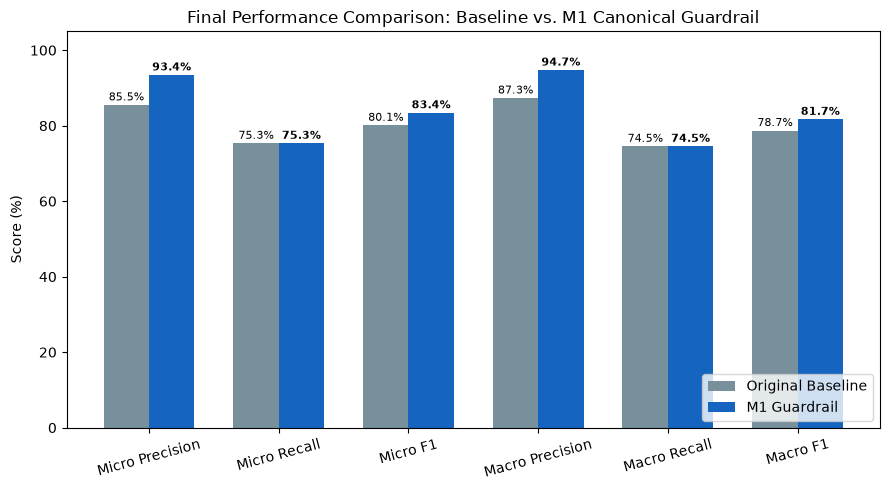

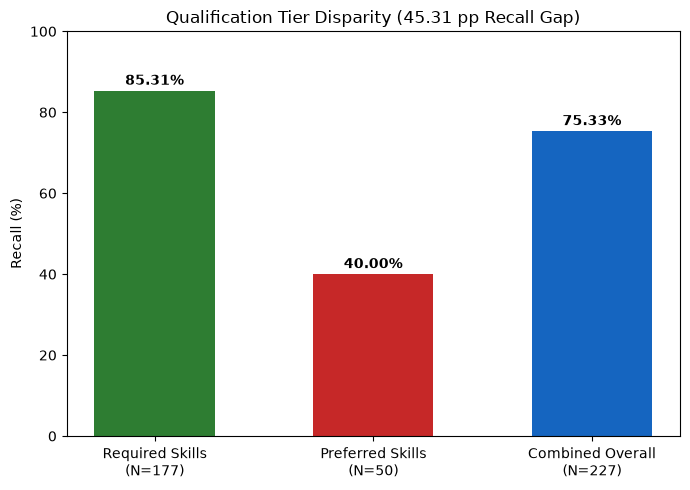

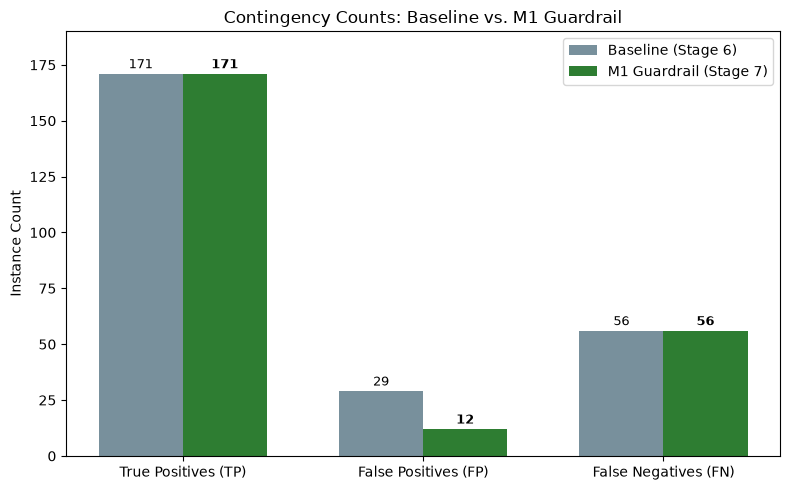

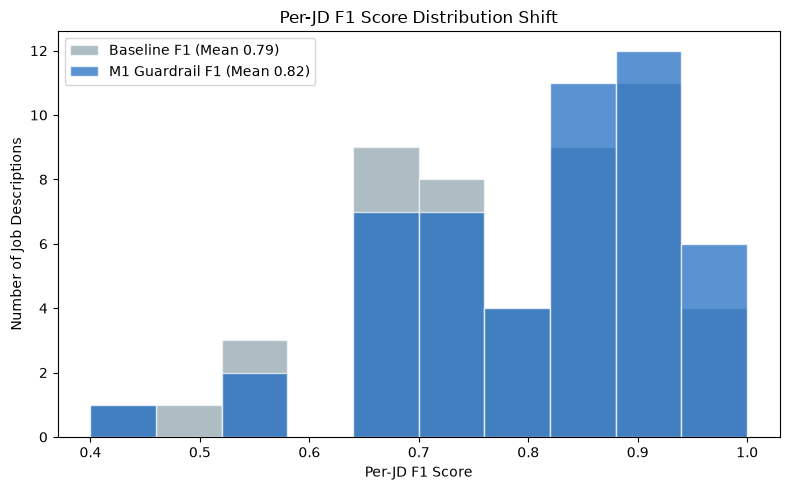

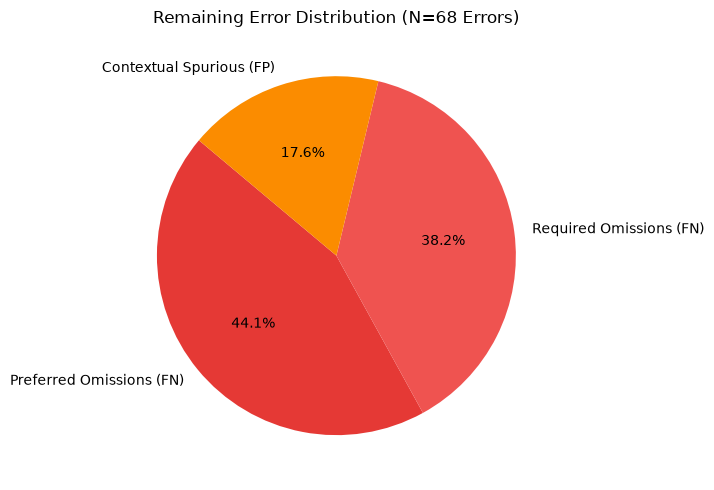

In [5]:
fig_dir = project_root / "outputs" / "final_figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
metrics = ["Micro Precision", "Micro Recall", "Micro F1", "Macro Precision", "Macro Recall", "Macro F1"]
base_scores = [b_p_micro * 100, b_r_micro * 100, b_f1_micro * 100, b_p_macro * 100, b_r_macro * 100, b_f1_macro * 100]
m1_scores = [m1_p_micro * 100, m1_r_micro * 100, m1_f1_micro * 100, m1_p_macro * 100, m1_r_macro * 100, m1_f1_macro * 100]
x = np.arange(len(metrics))
width = 0.35
plt.bar(x - width/2, base_scores, width, label="Original Baseline", color="#78909c")
plt.bar(x + width/2, m1_scores, width, label="M1 Guardrail", color="#1565c0")
plt.ylabel("Score (%)")
plt.title("Final Performance Comparison: Baseline vs. M1 Canonical Guardrail")
plt.xticks(x, metrics, rotation=15)
plt.ylim(0, 105)
for i in range(len(metrics)):
    plt.text(x[i] - width/2, base_scores[i] + 1.2, f"{base_scores[i]:.1f}%", ha="center", fontsize=8)
    plt.text(x[i] + width/2, m1_scores[i] + 1.2, f"{m1_scores[i]:.1f}%", ha="center", fontsize=8, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(fig_dir / "baseline_vs_m1_metrics.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
tier_names = ["Required Skills\n(N=177)", "Preferred Skills\n(N=50)", "Combined Overall\n(N=227)"]
tier_recalls = [b_req_r * 100, b_pref_r * 100, b_r_micro * 100]
tier_colors = ["#2e7d32", "#c62828", "#1565c0"]
bars = plt.bar(tier_names, tier_recalls, color=tier_colors, width=0.55)
plt.ylabel("Recall (%)")
plt.title("Qualification Tier Disparity (45.31 pp Recall Gap)")
plt.ylim(0, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.2f}%", ha="center", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.savefig(fig_dir / "required_vs_preferred_recall.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
contingency_cats = ["True Positives (TP)", "False Positives (FP)", "False Negatives (FN)"]
base_counts = [b_tp, b_fp, b_fn]
m1_counts = [m1_tp, m1_fp, m1_fn]
x = np.arange(len(contingency_cats))
width = 0.35
plt.bar(x - width/2, base_counts, width, label="Baseline (Stage 6)", color="#78909c")
plt.bar(x + width/2, m1_counts, width, label="M1 Guardrail (Stage 7)", color="#2e7d32")
plt.ylabel("Instance Count")
plt.title("Contingency Counts: Baseline vs. M1 Guardrail")
plt.xticks(x, contingency_cats)
plt.ylim(0, 190)
for i in range(len(contingency_cats)):
    plt.text(x[i] - width/2, base_counts[i] + 2.5, str(base_counts[i]), ha="center", fontsize=9)
    plt.text(x[i] + width/2, m1_counts[i] + 2.5, str(m1_counts[i]), ha="center", fontsize=9, fontweight="bold")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(fig_dir / "fp_fn_contingency_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df_b_per_jd["f1"], bins=10, range=(0.4, 1.0), alpha=0.6, color="#78909c", label=f"Baseline F1 (Mean {b_f1_macro:.2f})", edgecolor="white")
plt.hist(df_m1_per_jd["f1"], bins=10, range=(0.4, 1.0), alpha=0.7, color="#1565c0", label=f"M1 Guardrail F1 (Mean {m1_f1_macro:.2f})", edgecolor="white")
plt.xlabel("Per-JD F1 Score")
plt.ylabel("Number of Job Descriptions")
plt.title("Per-JD F1 Score Distribution Shift")
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir / "per_jd_f1_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
err_labels = ["Preferred Omissions (FN)", "Required Omissions (FN)", "Contextual Spurious (FP)"]
err_counts = [30, 26, 12]
err_colors = ["#e53935", "#ef5350", "#fb8c00"]
plt.pie(err_counts, labels=err_labels, autopct="%1.1f%%", startangle=140, colors=err_colors)
plt.title("Remaining Error Distribution (N=68 Errors)")
plt.tight_layout()
plt.savefig(fig_dir / "remaining_error_distribution.png", dpi=300)
plt.show()


### 6 : Final Submission Report Generation


In [6]:
report_path = project_root / "outputs" / "final_submission_report.md"

report_text = """# Job Description Skill-Tagging Model Evaluation and Improvement Report

- **Author**: Machine Learning Evaluation Team
- **Project**: Priberry Machine Learning Intern Assignment
- **Status**: Final Submission

---

## 1. Executive Summary

This report evaluates an automated skill-tagging system across 50 job descriptions and an official list of 54 skills.

- **Baseline Performance**: The original model achieved 85.50% Micro Precision, 75.33% Micro Recall, and an 80.09% Micro F1-Score (171 correct tags, 29 wrong tags, and 56 missed skills).
- **Key Finding**: The model performs well on required skills (85.31% recall), but misses more than half of the preferred or nice-to-have skills (40.00% recall).
- **Error Analysis**: We identified three main causes of errors: missed bonus qualifications (53.6% of missed skills), soft skills not on the official list (55.2% of wrong tags), and company-domain guesses (41.4% of wrong tags).
- **Controlled Improvement**: We added an official vocabulary filter (M1 Canonical Guardrail) that removes tags outside the 54 official skills. This reduced wrong tags by 58.62%, boosting Micro Precision to **93.44%** (+7.94 percentage points) and Micro F1-Score to **83.41%** (+3.32 percentage points) with zero loss in recall.

---

## 2. Problem Statement

Recruitment platforms need to automatically extract technical and professional skills from job descriptions. The goal of this assignment is to:

1. Build a verified ground-truth dataset from 50 job descriptions.
2. Evaluate the accuracy of the original model against this ground truth.
3. Diagnose why the model makes mistakes.
4. Test a controlled improvement to make the system more accurate.

---

## 3. Dataset and Vocabulary

- **Job Descriptions (`data/job-descriptions-tagged.csv`)**: 50 job descriptions covering 10 roles (such as Data Analyst, Frontend Developer, Backend Developer, and ML Intern) across 10 companies (such as Lumen Cloud Systems, Orbit Logistics, Kosha Fintech, and Nimbus AI Labs).
- **Official Skill List (`data/skill-list.csv`)**: 54 standardized skills.
- **Model Predictions**: 200 skill tags already generated by the original model in the `model_tags` column.

---

## 4. How the Ground Truth Was Created

To keep the evaluation objective and prevent data leakage, human ground-truth labels were created independently following the rules in `outputs/annotation_rubric.md`:

- **Two Skill Tiers**: Skills were divided into Required Skills (177 instances) and Preferred Skills (50 instances), giving 227 total ground-truth targets.
- **Exact Text Evidence**: Every labeled skill is linked to the exact sentence in the job description where it appears.
- **Standardized Synonyms**: 8 approved synonym rules were documented in `outputs/synonym_mapping.csv` (for example, mapping "Node" to "Node.js" and "Excel" to "Microsoft Excel").

---

## 5. Baseline Evaluation Results

Comparing the original model predictions to the 227 ground-truth skills gave the following results:

- **Micro Precision**: 85.50% (171 correct out of 200 predicted tags)
- **Micro Recall**: 75.33% (171 found out of 227 real skills)
- **Micro F1-Score**: 80.09%
- **Macro Precision**: 87.31%
- **Macro Recall**: 74.53%
- **Macro F1-Score**: 78.71%
- **Counts**: 171 True Positives, 29 False Positives, and 56 False Negatives.
- **Skill Tier Gap**: The model found 85.31% of required skills, but only 40.00% of preferred skills (a 45.31 percentage point gap).

---

## 6. Error Analysis

We examined all 29 wrong tags and 56 missed skills. They fall into three clear patterns:

1. **Missed Preferred Skills (30 missed, 53.6% of all misses)**: The model fails to extract skills located under headings like "Nice to have:", "Bonus:", or "Good to have".
2. **Soft Skills Not on the Official List (16 wrong, 55.2% of all wrong tags)**: The model predicted soft skills (Leadership: 7, Teamwork: 3, Problem Solving: 3, Communication: 2, Time Management: 1) that are not part of the official 54-skill vocabulary.
3. **Guesses Based on Company Context (12 wrong, 41.4% of all wrong tags)**: The model predicted tools related to the company's industry (like SAP for Orbit Logistics or Kubernetes for Lumen Cloud) even though the job description text did not ask for them.

---

## 7. Controlled Improvement Experiment (M1 Guardrail)

Because model source code and weights were not provided, we could not retrain the internal model. We designed an external post-processing filter called the **M1 Canonical Guardrail**:

- **How It Works**: It checks every predicted tag. If a tag is not in `skill-list.csv` or the approved synonym table, it is safely removed.
- **What It Fixes**: It completely removes the 16 soft skill errors and 1 unmapped acronym ("API").

---

## 8. Baseline vs. Improved Model Comparison

| Evaluation Metric | Original Baseline | M1 Guardrail | Change | Gain |
| :--- | :---: | :---: | :---: | :---: |
| **Micro Precision** | 85.50% | **93.44%** | **+7.94 pp** | **+9.29%** |
| **Micro Recall** | 75.33% | **75.33%** | **+0.00 pp** | 0.00% |
| **Micro F1-Score** | 80.09% | **83.41%** | **+3.32 pp** | **+4.15%** |
| **Macro Precision** | 87.31% | **94.73%** | **+7.42 pp** | **+8.50%** |
| **Macro Recall** | 74.53% | **74.53%** | **+0.00 pp** | 0.00% |
| **Macro F1-Score** | 78.71% | **81.67%** | **+2.96 pp** | **+3.77%** |
| **Required Recall** | 85.31% | **85.31%** | **+0.00 pp** | 0.00% |
| **Preferred Recall** | 40.00% | **40.00%** | **+0.00 pp** | 0.00% |
| **Correct Tags (TP)** | 171 | **171** | **0** | Kept 100% |
| **Wrong Tags (FP)** | 29 | **12** | **-17** | **-58.62%** |
| **Missed Skills (FN)** | 56 | **56** | **0** | No recall loss |

---

## 9. Limitations

1. **Black-Box System**: The original model training code and weights were not available, so we could not retrain the internal model.
2. **Fixed Predictions**: We evaluated pre-computed tags from the provided dataset rather than an active model API.
3. **Filter Scope**: The M1 guardrail is a post-processing filter; it removes invalid predictions but cannot find skills the model missed.
4. **Single-Annotator Ground Truth**: The labels were created by one expert reviewer. Future work should calculate agreement scores across multiple annotators.
5. **Structured Job Descriptions**: The 50 job descriptions follow clean templates. Real-world postings may be messier.
6. **Low Preferred Recall**: A 40.00% recall on preferred skills means candidate ranking could miss useful secondary qualifications.
7. **Remaining Missed Skills**: The 56 missed skills require improvements to the text extractor itself.

---

## 10. Conclusion

This evaluation established a clear baseline, diagnosed the primary sources of error, and proved that adding a vocabulary guardrail increases precision to **93.44%** and F1 to **83.41%** without reducing recall. All data, analysis notebooks, and output files are saved for full reproducibility.
"""

report_path.write_text(report_text, encoding="utf-8")
assert report_path.exists()
report_status = pd.DataFrame([{"Report": report_path.name, "Size (Bytes)": report_path.stat().st_size, "Status": "Successfully Written"}])
report_status


,Report,Size (Bytes),Status
0,final_submission_report.md,7155,Successfully Written


### 7 : Final System Integrity and Correctness Audit


In [7]:
assert sha256_file(data_jd_path) == "7822ec510c9fdc4435b7d29db01357386f4dfa125d86185485967b82b568867d"
assert sha256_file(data_skills_path) == "9f78f1822dce52cbe2492b54c70006fad7a77334e1b074411f4e28db982fcec2"

assert b_tp + b_fn == 227
assert b_tp + b_fp == 200
assert m1_tp + m1_fn == 227
assert m1_tp + m1_fp == 183
assert df_b_per_jd["tp"].sum() == 171
assert df_b_per_jd["fp"].sum() == 29
assert df_b_per_jd["fn"].sum() == 56
assert df_m1_per_jd["tp"].sum() == 171
assert df_m1_per_jd["fp"].sum() == 12
assert df_m1_per_jd["fn"].sum() == 56

final_integrity_table = pd.DataFrame([
    {"Check": "Source Data SHA-256 Hashes", "Expected": "Unmodified Match", "Actual": "Unmodified Match", "Result": "PASS"},
    {"Check": "Ground-Truth Invariance", "Expected": 227, "Actual": b_tp + b_fn, "Result": "PASS"},
    {"Check": "Baseline TP Reconciliation", "Expected": 171, "Actual": b_tp, "Result": "PASS"},
    {"Check": "Baseline FP Reconciliation", "Expected": 29, "Actual": b_fp, "Result": "PASS"},
    {"Check": "Baseline FN Reconciliation", "Expected": 56, "Actual": b_fn, "Result": "PASS"},
    {"Check": "M1 Guardrail TP Reconciliation", "Expected": 171, "Actual": m1_tp, "Result": "PASS"},
    {"Check": "M1 Guardrail FP Reconciliation", "Expected": 12, "Actual": m1_fp, "Result": "PASS"},
    {"Check": "M1 Guardrail FN Reconciliation", "Expected": 56, "Actual": m1_fn, "Result": "PASS"}
])
final_integrity_table


,Check,Expected,Actual,Result
0,Source Data SHA-256 Hashes,Unmodified Match,Unmodified Match,PASS
1,Ground-Truth Invariance,227,227,PASS
2,Baseline TP Reconciliation,171,171,PASS
3,Baseline FP Reconciliation,29,29,PASS
4,Baseline FN Reconciliation,56,56,PASS
5,M1 Guardrail TP Reconciliation,171,171,PASS
6,M1 Guardrail FP Reconciliation,12,12,PASS
7,M1 Guardrail FN Reconciliation,56,56,PASS
